# AI in Healthcare — Lab Assignment 6

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (128, 128)

# CHANGE THIS PATH
DATASET_DIR = "/run/media/sambhav/New Volume/Documents/UNI/4th year/Ai in Healthcare/ CSET343 Ai in  Healthcare/LAB 6/chest_xray/"

print("TensorFlow version:", tf.__version__)
print("Dataset directory:", DATASET_DIR)


TensorFlow version: 2.21.0
Dataset directory: /run/media/sambhav/New Volume/Documents/UNI/4th year/Ai in Healthcare/ CSET343 Ai in  Healthcare/LAB 6/chest_xray/


In [8]:
import os

print("Dataset exists:", os.path.isdir(DATASET_DIR))

if os.path.isdir(DATASET_DIR):
    print("\nDataset folders:", os.listdir(DATASET_DIR))

    for split in ["train", "test", "val"]:
        for category in ["NORMAL", "PNEUMONIA"]:
            folder = os.path.join(DATASET_DIR, split, category)

            if os.path.isdir(folder):
                images = [
                    f for f in os.listdir(folder)
                    if f.lower().endswith((".jpg", ".jpeg", ".png"))
                ]
                print(f"{split}/{category}: {len(images)} images")
            else:
                print(f"MISSING: {split}/{category}")
else:
    print("Dataset directory does not exist.")

Dataset exists: True

Dataset folders: ['chest_xray', 'test', 'train', 'val', '__MACOSX']
train/NORMAL: 1341 images
train/PNEUMONIA: 3875 images
test/NORMAL: 234 images
test/PNEUMONIA: 390 images
val/NORMAL: 8 images
val/PNEUMONIA: 8 images


In [9]:
class_names = ["NORMAL", "PNEUMONIA"]
splits = ["train", "test", "val"]

records = []

for split in splits:

    for label, class_name in enumerate(class_names):

        class_dir = os.path.join(DATASET_DIR, split, class_name)

        if not os.path.isdir(class_dir):
            print(f"Warning: folder not found -> {class_dir}")
            continue

        for fname in os.listdir(class_dir):

            if fname.lower().endswith((".jpg", ".jpeg", ".png")):

                records.append({
                    "path": os.path.join(class_dir, fname),
                    "class_name": class_name,
                    "label": label,
                    "split": split
                })

# Create DataFrame
df = pd.DataFrame(
    records,
    columns=["path", "class_name", "label", "split"]
)

print("Total images:", len(df))

print("\nImages per class:")
print(df["class_name"].value_counts())

print("\nImages per split:")
print(df.groupby(["split", "class_name"]).size())

print("\nFirst five records:")
display(df.head())

Total images: 5856

Images per class:
class_name
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Images per split:
split  class_name
test   NORMAL         234
       PNEUMONIA      390
train  NORMAL        1341
       PNEUMONIA     3875
val    NORMAL           8
       PNEUMONIA        8
dtype: int64

First five records:


,path,class_name,label,split
0,/run/media/sambhav/New Volume/Documents/UNI/4t...,NORMAL,0,train
1,/run/media/sambhav/New Volume/Documents/UNI/4t...,NORMAL,0,train
2,/run/media/sambhav/New Volume/Documents/UNI/4t...,NORMAL,0,train
3,/run/media/sambhav/New Volume/Documents/UNI/4t...,NORMAL,0,train
4,/run/media/sambhav/New Volume/Documents/UNI/4t...,NORMAL,0,train


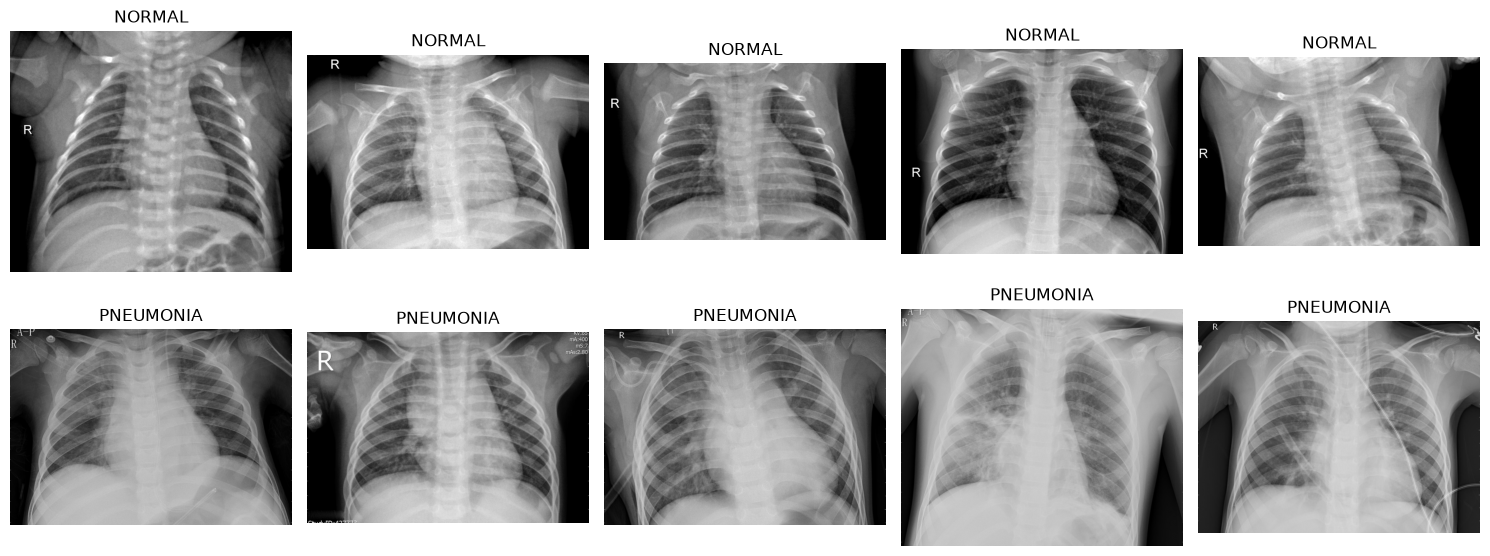

In [10]:
# Display 5 random images from each class

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for row, class_name in enumerate(class_names):
    subset = df[df["class_name"] == class_name]
    samples = subset.sample(min(5, len(subset)), random_state=SEED)

    for col, (_, item) in enumerate(samples.iterrows()):
        img = Image.open(item["path"]).convert("L")
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


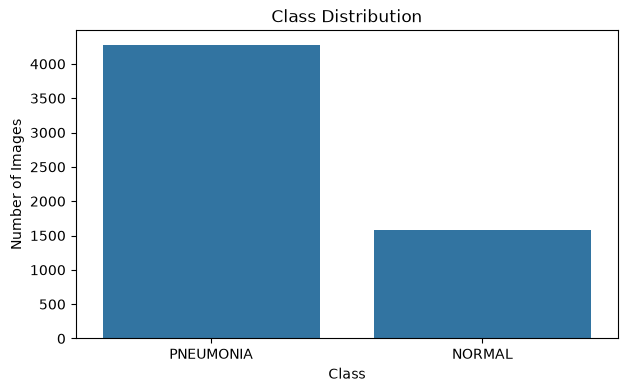

In [11]:
# Class balance visualization

counts = df["class_name"].value_counts()

plt.figure(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()


## Task 2 — Data Preprocessing

Images are resized to **128 × 128** and converted to grayscale.

The assignment also requires:
- HOG — Histogram of Oriented Gradients
- LBP — Local Binary Patterns
- GLCM — Gray-Level Co-occurrence Matrix

The CNN itself uses normalized image pixels, while the handcrafted feature functions below demonstrate the requested feature extraction methods.


In [12]:
def load_image(path, size=IMG_SIZE):
    img = Image.open(path).convert("L")
    img = img.resize(size)
    arr = np.asarray(img, dtype=np.float32) / 255.0
    return arr

def extract_hog_features(img):
    return hog(
        img,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

def extract_lbp_features(img):
    img_uint8 = (img * 255).astype(np.uint8)
    radius = 1
    points = 8 * radius
    lbp = local_binary_pattern(img_uint8, points, radius, method="uniform")
    n_bins = points + 2
    hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, n_bins + 1),
        range=(0, n_bins)
    )
    hist = hist.astype(np.float32)
    hist /= (hist.sum() + 1e-8)
    return hist

def extract_glcm_features(img):
    img_uint8 = (img * 255).astype(np.uint8)
    # Quantize image to 8 gray levels for a compact GLCM
    quantized = (img_uint8 // 32).astype(np.uint8)

    glcm = graycomatrix(
        quantized,
        distances=[1],
        angles=[0],
        levels=8,
        symmetric=True,
        normed=True
    )

    properties = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]
    return np.array(
        [graycoprops(glcm, prop)[0, 0] for prop in properties],
        dtype=np.float32
    )


In [13]:
# Demonstrate HOG, LBP and GLCM on one image

sample_path = df.iloc[0]["path"]
sample_img = load_image(sample_path)

hog_features = extract_hog_features(sample_img)
lbp_features = extract_lbp_features(sample_img)
glcm_features = extract_glcm_features(sample_img)

print("HOG feature vector length:", len(hog_features))
print("LBP feature vector length:", len(lbp_features))
print("GLCM feature vector:", glcm_features)


HOG feature vector length: 1764
LBP feature vector length: 10
GLCM feature vector: [0.28930858 0.25559792 0.8755634  0.34442782 0.9353596 ]


In [14]:
# Prepare CNN image arrays

X = np.stack([load_image(path) for path in df["path"]])
y = df["label"].values

# CNN expects: samples x height x width x channels
X = X[..., np.newaxis]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (5856, 128, 128, 1)
y shape: (5856,)


In [15]:
# Split: 70% training, 15% validation, 15% testing

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print("Training:", X_train.shape[0])
print("Validation:", X_val.shape[0])
print("Testing:", X_test.shape[0])


Training: 4099
Validation: 878
Testing: 879


## Task 3 — Baseline CNN Model

The CNN contains convolutional layers for feature extraction followed by pooling and fully connected layers for classification.


In [16]:
def build_cnn():
    model = models.Sequential([
        layers.Input(shape=(128, 128, 1)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn = build_cnn()
cnn.summary()


E0000 00:00:1793544429.160057   56791 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793544429.160349   58877 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1793544429.176516   56791 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,193 (12.60 MB)

 Trainable params: 3,304,193 (12.60 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Train the CNN

history = cnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)


Epoch 1/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 14s 105ms/step - accuracy: 0.8624 - loss: 0.3290 - val_accuracy: 0.9157 - val_loss: 0.2112
Epoch 2/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step - accuracy: 0.9261 - loss: 0.1890 - val_accuracy: 0.9328 - val_loss: 0.1874
Epoch 3/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step - accuracy: 0.9402 - loss: 0.1615 - val_accuracy: 0.9305 - val_loss: 0.1845
Epoch 4/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 13s 102ms/step - accuracy: 0.9458 - loss: 0.1421 - val_accuracy: 0.9465 - val_loss: 0.1432
Epoch 5/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 13s 102ms/step - accuracy: 0.9544 - loss: 0.1219 - val_accuracy: 0.9499 - val_loss: 0.1281
Epoch 6/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 13s 102ms/step - accuracy: 0.9590 - loss: 0.1082 - val_accuracy: 0.9522 - val_loss: 0.1336
Epoch 7/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 13s 103ms/step - accuracy: 0.9646 - loss: 0.0948 - val_accuracy: 0.9567 - val_loss: 0.1287
Epoch 8/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 13s 102ms/step - accuracy: 0.9680 - loss: 0

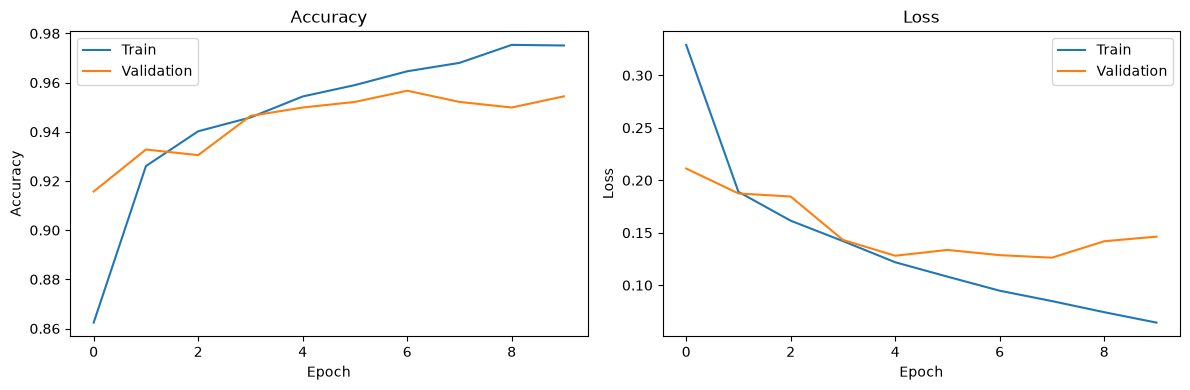

In [18]:
# Plot training history

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [19]:
# Evaluate on test set

probabilities = cnn.predict(X_test, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, zero_division=0)
recall = recall_score(y_test, predictions, zero_division=0)
f1 = f1_score(y_test, predictions, zero_division=0)
auroc = roc_auc_score(y_test, probabilities)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "AUROC"],
    "Score": [accuracy, precision, recall, f1, auroc]
})

results


,Metric,Score
0,Accuracy,0.951081
1,Precision,0.965732
2,Recall,0.967239
3,F1-score,0.966485
4,AUROC,0.988896


In [20]:
# Classification report

print(classification_report(
    y_test,
    predictions,
    target_names=class_names,
    zero_division=0
))


              precision    recall  f1-score   support

      NORMAL       0.91      0.91      0.91       238
   PNEUMONIA       0.97      0.97      0.97       641

    accuracy                           0.95       879
   macro avg       0.94      0.94      0.94       879
weighted avg       0.95      0.95      0.95       879



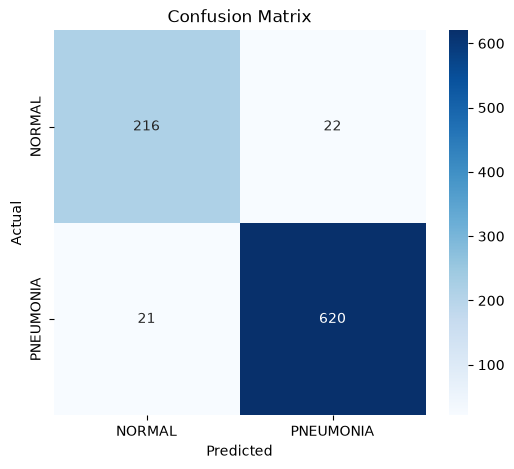

Rows = actual classes, columns = predicted classes.
False positives: Normal images predicted as Pneumonia.
False negatives: Pneumonia images predicted as Normal.


In [21]:
# Confusion matrix

cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print("Rows = actual classes, columns = predicted classes.")
print("False positives: Normal images predicted as Pneumonia.")
print("False negatives: Pneumonia images predicted as Normal.")
